## Curso Integral de econometría
### Series de tiempo con Python
### Tema: Modelos multivariantes de series de tiempo
### Subtema: Modelo VAR y VEC
### Sesión: 14
### Fecha: 28/10/2026
### Docente: Alexis Adonai Morales Alberto

In [1]:
# Modulos a importar

import os
import json
import warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm

# Clases necesarias 

from pathlib import Path
from getpass import getpass
from itertools import permutations
from matplotlib.dates import YearLocator, DateFormatter
from IPython.display import display
from scipy.stats import chi2, norm, jarque_bera
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_coint_rank
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.graphics.tsaplots import plot_acf

In [2]:
# Configuraciones iniciales 

BASE = Path(
    "E:\Econometrics Data Lab\Curso integral de econometría\Series de tiempo\ST_SEP26"
)
FUENTE = os.environ.get('S14_FUENTE', 'CSV').upper()
SALIDA = BASE / 'Resultados' / 'S14_VAR_VEC'
DATOS = BASE / 'Datos'
SALIDA.mkdir(parents=True, exist_ok=True)
DATOS.mkdir(parents=True, exist_ok=True)
ALFA = 0.05
MAX_REZAGOS = 8
H = 10
B = 5000
SEMILLA = 13026
Series = pd.DataFrame({'Variable':['PIB','Consumo','Inversion'],
    'Clave':['736181','738020','738065'], 'Topico':['600609','633186','633258']})
Nombres = Series.Variable.tolist()
Colores = ['#003057','#08989C','#F04A1D']
plt.rcParams.update({'font.family':'DejaVu Sans','figure.dpi':110,'savefig.dpi':200,
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
display(Series)


,Variable,Clave,Topico
0,PIB,736181,600609
1,Consumo,738020,633186
2,Inversion,738065,633258


In [3]:
# Consulta BIE 

if FUENTE == 'BIE':
    Token = os.environ.get('INEGI_TOKEN','af847734-746b-8eb8-f0e6-4070cc851e47').strip()
    if not Token:
        Token = getpass('Token INEGI (entrada oculta): ').strip()
    if not Token:
        raise ValueError('Token vacío. Use INEGI_TOKEN o FUENTE=CSV.')
    Columnas = {}
    for Fila in Series.itertuples(index=False):
        URL = ('https://www.inegi.org.mx/app/api/indicadores/desarrolladores/jsonxml/'
               f'INDICATOR/{Fila.Clave}/es/00/false/BIE-BISE/2.0/{Token}?type=json')
        try:
            Respuesta = requests.get(URL,timeout=(10,45))
            Respuesta.raise_for_status()
            Bruto = Respuesta.json()
        except (requests.RequestException,ValueError):
            raise RuntimeError('Fallo BIE: revise conexión y token. No se imprime URL privada.') from None
        Candidatas = [s for s in Bruto.get('Series',[]) if str(s.get('INDICADOR'))==Fila.Clave]
        if len(Candidatas)!=1:
            raise ValueError('La respuesta no identifica una única serie solicitada.')
        Serie = Candidatas[0]
        if (str(Serie.get('FREQ')),str(Serie.get('UNIT')),str(Serie.get('TOPIC'))) != ('4','1054',Fila.Topico):
            raise ValueError('Metadatos incompatibles: revise frecuencia, unidad y tópico.')
        Observaciones = pd.DataFrame(Serie['OBSERVATIONS'])
        Partes = Observaciones.TIME_PERIOD.str.extract(r'^(\d{4})[/-](0?[1-4])$')
        if Partes.isna().any().any():
            raise ValueError('Periodo trimestral no reconocido.')
        Indice = pd.PeriodIndex(Partes[0]+'Q'+Partes[1].astype(int).astype(str),freq='Q-DEC')
        if Indice.duplicated().any():
            raise ValueError('Periodos duplicados en BIE.')
        Columnas[Fila.Variable] = pd.Series(pd.to_numeric(Observaciones.OBS_VALUE,errors='coerce').to_numpy(),index=Indice).sort_index()
        (DATOS/f'BIE_{Fila.Variable}_{Fila.Clave}.json').write_text(json.dumps(Bruto,ensure_ascii=False,indent=2),encoding='utf-8')
        print(Fila.Variable, 'descargada; actualización fuente:', Serie['LASTUPDATE'])
    Datos_Fuente = pd.concat(Columnas,axis=1)
    Datos_Fuente.index.name='Trimestre'
    Datos_Fuente.to_csv(DATOS/'BIE_VAR_VEC.csv',encoding='utf-8-sig')
    del Token, URL  # No dejar credencial en los objetos que se mostrarán.
elif FUENTE == 'CSV':
    Datos_Fuente = pd.read_csv(DATOS/'BIE_VAR_VEC.csv',index_col='Trimestre')
    Datos_Fuente.index = pd.PeriodIndex(Datos_Fuente.index,freq='Q-DEC')
else:
    raise ValueError('FUENTE debe ser BIE o CSV.')
print('2020/02 en INEGI corresponde a 2020T2; no a febrero.')
display(Datos_Fuente.head(), Datos_Fuente.tail())


2020/02 en INEGI corresponde a 2020T2; no a febrero.


,PIB,Consumo,Inversion
Trimestre,,,
1980Q1,1.029088e+07,NaN,NaN
1980Q2,1.032008e+07,NaN,NaN
1980Q3,1.056115e+07,NaN,NaN
1980Q4,1.089193e+07,NaN,NaN
1981Q1,1.122989e+07,NaN,NaN


,PIB,Consumo,Inversion
Trimestre,,,
2025Q2,2.548058e+07,1.815492e+07,5.779339e+06
2025Q3,2.545387e+07,1.833475e+07,5.751173e+06
2025Q4,2.569449e+07,1.851368e+07,5.788316e+06
2026Q1,2.560645e+07,1.837617e+07,5.735407e+06
2026Q2,2.597119e+07,1.853518e+07,5.982842e+06


In [4]:
# Validación de los datos 

Faltantes = Datos_Fuente.isna().sum().to_frame('Faltantes')
display(Faltantes)
Completos = Datos_Fuente[Nombres].dropna()
if Completos.empty:
    raise ValueError('No hay ventana común.')
Indice_Comun = pd.period_range(max(Completos.index.min(),pd.Period('1993Q1')),Completos.index.max(),freq='Q-DEC')
Datos = Datos_Fuente[Nombres].reindex(Indice_Comun).astype(float)
Datos.index.name = 'Trimestre'
if Datos.index.duplicated().any() or Datos.isna().any().any():
    raise ValueError('Duplicados o huecos interiores. No se interpola ni se comprime el calendario.')
if len(Datos)<80 or not np.isfinite(Datos).all().all() or (Datos<=0).any().any():
    raise ValueError('Se requieren 80 trimestres positivos y finitos como mínimo.')
print('Muestra:',Datos.index[0],'a',Datos.index[-1],'; T =',len(Datos))
print('Se recortan extremos sin cobertura común; no se divide entrenamiento/prueba.')
Datos.to_csv(SALIDA/'01_niveles.csv',encoding='utf-8-sig')

,Faltantes
PIB,0
Consumo,52
Inversion,52


Muestra: 1993Q1 a 2026Q2 ; T = 134
Se recortan extremos sin cobertura común; no se divide entrenamiento/prueba.


,count,mean,std,min,25%,50%,75%,max
PIB,133.0,0.475176,2.597949,-20.964020,0.058366,0.669056,1.088025,14.471375
Consumo,133.0,0.570632,2.552577,-21.906416,0.209742,0.721215,1.300285,11.850185
Inversion,133.0,0.515788,5.287701,-33.448225,-0.574737,1.008656,2.580170,18.079349


,PIB,Consumo,Inversion
PIB,1.000000,0.947758,0.826907
Consumo,0.947758,1.000000,0.815265
Inversion,0.826907,0.815265,1.000000


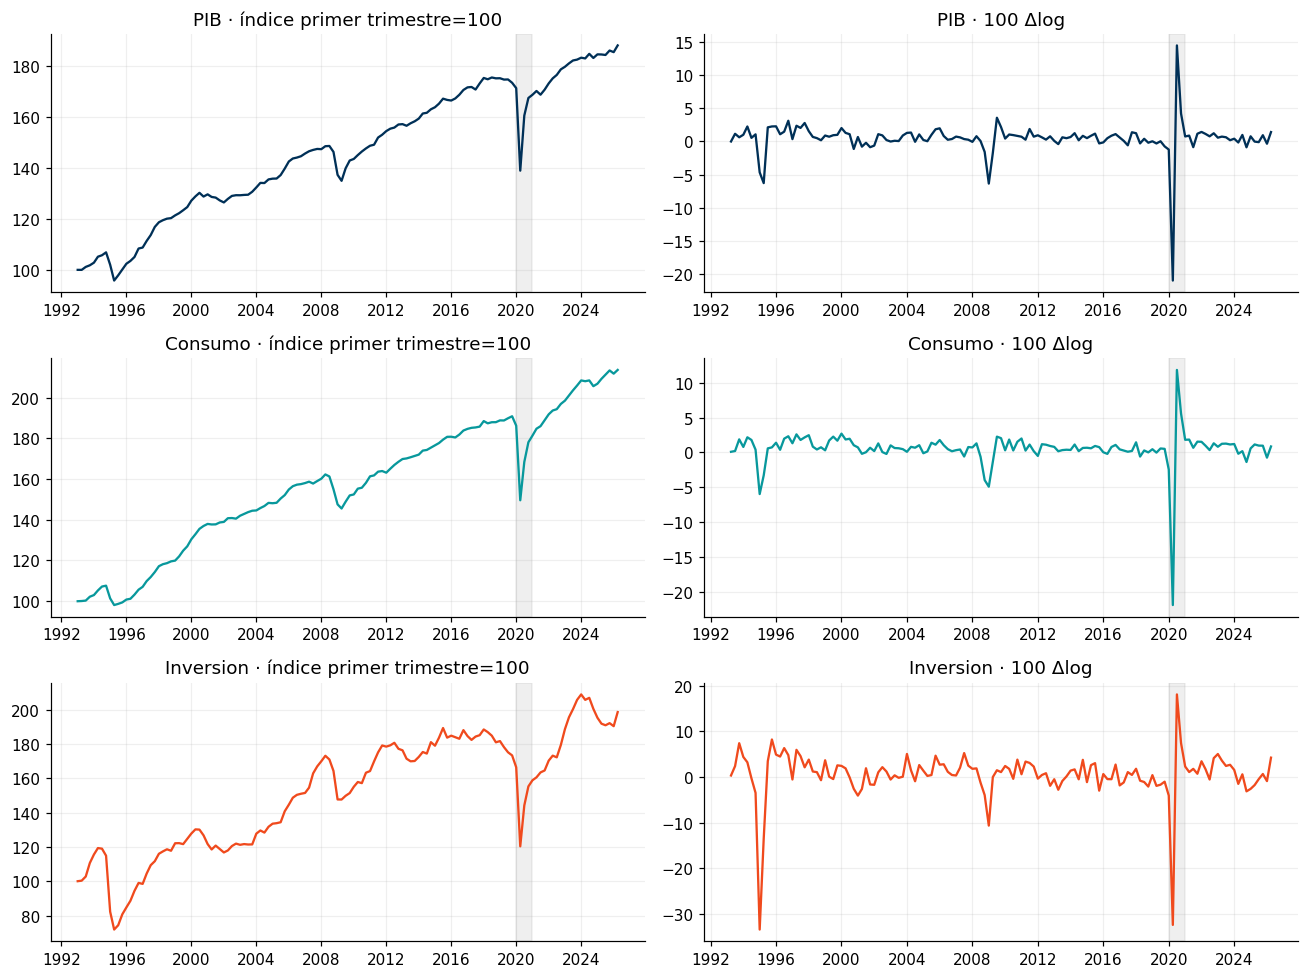

Una correlación de niveles no demuestra cointegración. La pandemia permanece en la muestra.


In [5]:
# Transformación logarítmica y exploración 

Logaritmos = np.log(Datos)
Crecimientos = 100*Logaritmos.diff().dropna()
Descriptivos = Crecimientos.describe().T
Correlaciones = Crecimientos.corr()
display(Descriptivos)
display(Correlaciones)
Logaritmos.to_csv(SALIDA/'02_logaritmos.csv',encoding='utf-8-sig')
Crecimientos.to_csv(SALIDA/'02_crecimientos.csv',encoding='utf-8-sig')
Descriptivos.to_csv(SALIDA/'02_descriptivos.csv',encoding='utf-8-sig')
Fig_Exploracion, Ejes = plt.subplots(3,2,figsize=(12,9))
for j,Nombre in enumerate(Nombres):
    Ejes[j,0].plot(Datos.index.to_timestamp(),100*Datos[Nombre]/Datos[Nombre].iloc[0],color=Colores[j])
    Ejes[j,1].plot(Crecimientos.index.to_timestamp(),Crecimientos[Nombre],color=Colores[j])
    Ejes[j,0].set_title(Nombre+' · índice primer trimestre=100')
    Ejes[j,1].set_title(Nombre+' · 100 Δlog')
    for ax in Ejes[j]:
        ax.axvspan(pd.Timestamp('2020-01-01'),pd.Timestamp('2020-12-31'),alpha=.12,color='gray')
Fig_Exploracion.tight_layout()
for Ext in ['png','svg']:
    Fig_Exploracion.savefig(SALIDA/f'02_exploracion.{Ext}',bbox_inches='tight')
plt.show()
print('Una correlación de niveles no demuestra cointegración. La pandemia permanece en la muestra.')


In [6]:
# Pruebas de estacionariedad 

## ADF 

Registros_ADF = []
for Nombre in Nombres:
    for Transformacion,x,Reg in [('Log_nivel',Logaritmos[Nombre],'ct'),('Delta_log',Logaritmos[Nombre].diff().dropna(),'c')]:
        with warnings.catch_warnings(record=True) as Avisos:
            warnings.simplefilter('always')
            ADF = adfuller(x,regression=Reg,autolag='BIC')
        Registros_ADF.append([Nombre,Transformacion,Reg,ADF[0],ADF[1],ADF[2],ADF[3],
            'Rechazar raíz unitaria' if ADF[1]<ALFA else 'No rechazar raíz unitaria',
            ' | '.join(str(a.message) for a in Avisos)])
Prueba_ADF = pd.DataFrame(Registros_ADF,columns=['Variable','Transformacion','Deterministicos','Estadistico','p','Rezagos','n','Lectura','Avisos'])
display(Prueba_ADF.drop(columns='Avisos'))
Prueba_ADF.to_csv(SALIDA/'03_ADF.csv',index=False,encoding='utf-8-sig')
print('No rechazar raíz no demuestra I(1). Las tablas de ADF son no estándar; no use una t ordinaria.')


,Variable,Transformacion,Deterministicos,Estadistico,p,Rezagos,n,Lectura
0,PIB,Log_nivel,ct,-3.322293,6.266881e-02,0,133,No rechazar raíz unitaria
1,PIB,Delta_log,c,-13.233485,9.480767e-25,0,132,Rechazar raíz unitaria
2,Consumo,Log_nivel,ct,-2.549619,3.036142e-01,0,133,No rechazar raíz unitaria
3,Consumo,Delta_log,c,-11.747965,1.228491e-21,0,132,Rechazar raíz unitaria
4,Inversion,Log_nivel,ct,-2.675194,2.465259e-01,0,133,No rechazar raíz unitaria
5,Inversion,Delta_log,c,-9.448915,4.673471e-16,0,132,Rechazar raíz unitaria


No rechazar raíz no demuestra I(1). Las tablas de ADF son no estándar; no use una t ordinaria.


In [7]:
## KPSS 

Registros_KPSS = []
for Nombre in Nombres:
    for Transformacion,x,Reg in [('Log_nivel',Logaritmos[Nombre],'ct'),('Delta_log',Logaritmos[Nombre].diff().dropna(),'c')]:
        with warnings.catch_warnings(record=True) as Avisos:
            warnings.simplefilter('always')
            KPSS = kpss(x,regression=Reg,nlags='auto')
        Registros_KPSS.append([Nombre,Transformacion,KPSS[0],KPSS[1],KPSS[2],
            'Rechazar estacionariedad' if KPSS[1]<ALFA else 'No rechazar estacionariedad',
            ' | '.join(str(a.message) for a in Avisos)])
Prueba_KPSS = pd.DataFrame(Registros_KPSS,columns=['Variable','Transformacion','Estadistico','p_tabla','Rezagos','Lectura','Avisos'])
Integracion = Prueba_ADF.merge(Prueba_KPSS,on=['Variable','Transformacion'],suffixes=('_ADF','_KPSS'))
Compatible_I1 = {}
for Nombre in Nombres:
    n = Integracion.query('Variable==@Nombre and Transformacion=="Log_nivel"').iloc[0]
    d = Integracion.query('Variable==@Nombre and Transformacion=="Delta_log"').iloc[0]
    Compatible_I1[Nombre] = bool(n['p']>=ALFA and n.p_tabla<ALFA and d['p']<ALFA and d.p_tabla>=ALFA)
display(Prueba_KPSS.drop(columns='Avisos'),pd.Series(Compatible_I1,name='Compatible con I(1)'))
Prueba_KPSS.to_csv(SALIDA/'03_KPSS.csv',index=False,encoding='utf-8-sig')
print('KPSS 0.01/0.10 pueden ser cotas de tablas. No son siempre p-valores exactos.')
print('Discordancias, rupturas e I(2) requieren revisión; la regla no constituye prueba automática de integración.')


,Variable,Transformacion,Estadistico,p_tabla,Rezagos,Lectura
0,PIB,Log_nivel,0.285942,0.01,6,Rechazar estacionariedad
1,PIB,Delta_log,0.101591,0.10,7,No rechazar estacionariedad
2,Consumo,Log_nivel,0.315734,0.01,6,Rechazar estacionariedad
3,Consumo,Delta_log,0.104474,0.10,5,No rechazar estacionariedad
4,Inversion,Log_nivel,0.244646,0.01,6,Rechazar estacionariedad
5,Inversion,Delta_log,0.034470,0.10,1,No rechazar estacionariedad


PIB          True
Consumo      True
Inversion    True
Name: Compatible con I(1), dtype: bool

KPSS 0.01/0.10 pueden ser cotas de tablas. No son siempre p-valores exactos.
Discordancias, rupturas e I(2) requieren revisión; la regla no constituye prueba automática de integración.


In [8]:
# Identificación de rezagos del VAR 

Seleccion_VAR = VAR(Crecimientos).select_order(maxlags=MAX_REZAGOS,trend='c')
Criterios_VAR = pd.DataFrame(Seleccion_VAR.ics).rename_axis('p')
p_VAR = int(Seleccion_VAR.selected_orders['bic'])
print(Seleccion_VAR.summary())
print('BIC selecciona p =',p_VAR,'para CRECIMIENTOS; no para log-niveles.')
print('El mínimo BIC equilibra ajuste y dimensión. No certifica errores blancos.')
Criterios_VAR.to_csv(SALIDA/'04_VAR_criterios.csv',encoding='utf-8-sig')


 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0       2.750       2.818       15.65       2.778
1       2.471      2.742*       11.83      2.581*
2      2.441*       2.916      11.49*       2.634
3       2.531       3.210       12.58       2.807
4       2.596       3.479       13.44       2.955
5       2.665       3.751       14.43       3.106
6       2.728       4.017       15.40       3.252
7       2.831       4.324       17.15       3.438
8       2.870       4.567       17.93       3.559
-------------------------------------------------
BIC selecciona p = 1 para CRECIMIENTOS; no para log-niveles.
El mínimo BIC equilibra ajuste y dimensión. No certifica errores blancos.


In [9]:
# Estimación del modelo VAR(1) 

Modelo_VAR = VAR(Crecimientos).fit(p_VAR,trend='c')
print(Modelo_VAR.summary())
Coeficientes_VAR = Modelo_VAR.params
Errores_VAR = Modelo_VAR.stderr
p_valores_VAR = Modelo_VAR.pvalues
print('Columnas = ecuaciones dependientes; filas = constante o variable rezagada.')
display(Coeficientes_VAR)


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Wed, 28, Oct, 2026
Time:                     19:31:21
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    3.70600
Nobs:                     132.000    HQIC:                   3.55042
Log likelihood:          -777.199    FPE:                    31.3114
AIC:                      3.44393    Det(Omega_mle):         28.6291
--------------------------------------------------------------------
Results for equation PIB
                  coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------
const                0.631291         0.223333            2.827           0.005
L1.PIB              -0.607459         0.271985           -2.233           0.026
L1.Consumo          -0.004638         0.269303           -0.017   

,PIB,Consumo,Inversion
const,0.631291,0.635357,0.750521
L1.PIB,-0.607459,-0.539747,-1.177403
L1.Consumo,-0.004638,0.177857,-0.014242
L1.Inversion,0.275780,0.185362,0.668465


,PIB,Consumo,Inversion
Trimestre,,,
1993Q3,0.434197,-0.503946,1.408998
1993Q4,0.043619,1.392108,6.419320
1994Q1,-1.273450,-1.209064,-0.554581
1994Q2,1.031795,1.135409,0.729439
1994Q3,0.403088,1.396476,-0.500914


,PIB,Consumo,Inversion
PIB,6.115984,5.929892,9.973172
Consumo,5.929892,6.327160,10.141952
Inversion,9.973172,10.141952,24.751918


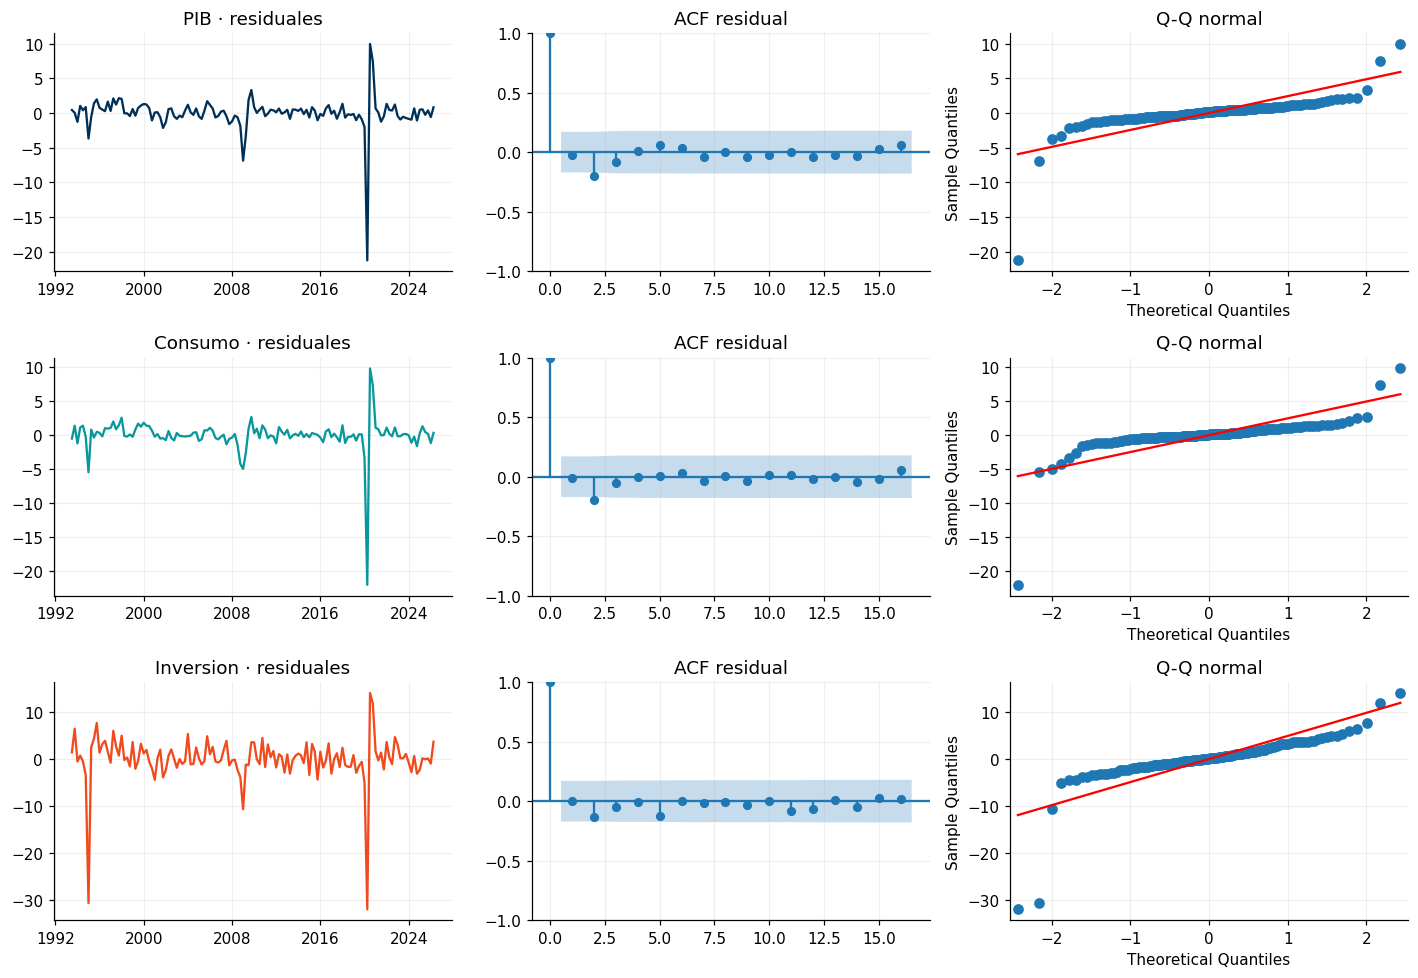

In [10]:
# Residuales VAR: Trayectoria, ACF y Q-Q

Residuos_VAR = Modelo_VAR.resid
Sigma_VAR = pd.DataFrame(Modelo_VAR.sigma_u,index=Nombres,columns=Nombres)
display(Residuos_VAR.head(),Sigma_VAR)
Fig_Res_VAR,Ejes = plt.subplots(3,3,figsize=(13,9))
for j,Nombre in enumerate(Nombres):
    Ejes[j,0].plot(Residuos_VAR.index.to_timestamp(),Residuos_VAR[Nombre],color=Colores[j]);Ejes[j,0].set_title(Nombre+' · residuales')
    Ejes[j,0].xaxis.set_major_locator(YearLocator(8));Ejes[j,0].xaxis.set_major_formatter(DateFormatter('%Y'))
    plot_acf(Residuos_VAR[Nombre],lags=16,ax=Ejes[j,1],title='ACF residual')
    sm.qqplot(Residuos_VAR[Nombre],line='s',ax=Ejes[j,2]);Ejes[j,2].set_title('Q-Q normal')
Fig_Res_VAR.tight_layout()
for Ext in ['png','svg']:
    Fig_Res_VAR.savefig(SALIDA/f'06_VAR_residuales.{Ext}',bbox_inches='tight')
plt.show()
Residuos_VAR.to_csv(SALIDA/'06_VAR_residuales.csv',encoding='utf-8-sig')


In [11]:
# Validaciones 

## Portmantaeu VAR: autocorrelación conjunta de errores 

Filas_Blancura_VAR = []
for h in [max(8,p_VAR+1),max(12,p_VAR+1)]:
    Prueba = Modelo_VAR.test_whiteness(nlags=h,adjusted=True)
    print(Prueba.summary())
    Filas_Blancura_VAR.append([h,Prueba.test_statistic,Prueba.df,Prueba.pvalue,
        'Rechazar: revisar dinámica' if Prueba.pvalue<ALFA else 'No se detecta autocorrelación conjunta'])
Blancura_VAR = pd.DataFrame(Filas_Blancura_VAR,columns=['h','Q_ajustado','gl','p','Lectura'])
display(Blancura_VAR)
Blancura_VAR.to_csv(SALIDA/'06_VAR_Portmanteau.csv',index=False,encoding='utf-8-sig')
print('No rechazar no prueba independencia ni homocedasticidad. La aproximación presupone un modelo adecuado.')


Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 8 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         58.53          82.53   0.636 63
----------------------------------------
Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         78.77          123.2   0.933 99
----------------------------------------


,h,Q_ajustado,gl,p,Lectura
0,8,58.531198,63,0.636133,No se detecta autocorrelación conjunta
1,12,78.770804,99,0.933312,No se detecta autocorrelación conjunta


No rechazar no prueba independencia ni homocedasticidad. La aproximación presupone un modelo adecuado.


In [12]:
## Normalidad 

Normalidad_VAR = Modelo_VAR.test_normality()
print(Normalidad_VAR.summary())
JB_VAR = pd.DataFrame([[n,*jarque_bera(Residuos_VAR[n])] for n in Nombres],columns=['Variable','JB','p'])
display(JB_VAR)
JB_VAR.to_csv(SALIDA/'06_VAR_JB_marginal.csv',index=False,encoding='utf-8-sig')
print('H0: normalidad. p<.05 rechaza. Colas/asimetría pueden limitar inferencia y bandas gaussianas.')
print('Un rechazo NO implica por sí solo inconsistencia de MCO; tampoco se debe ignorar al pronosticar.')


normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
     1.728e+04          12.59   0.000  6
----------------------------------------


,Variable,JB,p
0,PIB,11132.348305,0.0
1,Consumo,12710.676696,0.0
2,Inversion,3281.301959,0.0


H0: normalidad. p<.05 rechaza. Colas/asimetría pueden limitar inferencia y bandas gaussianas.
Un rechazo NO implica por sí solo inconsistencia de MCO; tampoco se debe ignorar al pronosticar.


In [13]:
## ARCH - LM (Heterocedasticidad condicional autorregresiva)

Filas_ARCH_VAR = []
for Nombre in Nombres:
    for q in [4,8]:
        LM,p_LM,F,p_F = het_arch(Residuos_VAR[Nombre],nlags=q,ddof=0)
        Filas_ARCH_VAR.append([Nombre,q,LM,p_LM,F,p_F])
ARCH_VAR = pd.DataFrame(Filas_ARCH_VAR,columns=['Variable','q','LM','p_LM','F_auxiliar','p_F_auxiliar'])
ARCH_VAR['p_Holm'] = multipletests(ARCH_VAR.p_LM,method='holm')[1]
display(ARCH_VAR)
ARCH_VAR.to_csv(SALIDA/'06_VAR_ARCH_marginal.csv',index=False,encoding='utf-8-sig')
print('LM usa n_aux*R² y gl=q; no se aplica corrección de grados ad hoc al modelo generado.')
print('No rechazar ARCH marginal no descarta cambios en las covarianzas entre ecuaciones.')


,Variable,q,LM,p_LM,F_auxiliar,p_F_auxiliar,p_Holm
0,PIB,4,7.119454,0.129709,1.811071,0.130917,0.778252
1,PIB,8,6.974180,0.539421,0.856681,0.555234,1.000000
2,Consumo,4,6.590649,0.159168,1.669249,0.161389,0.795838
3,Consumo,8,6.516835,0.589541,0.797387,0.606024,1.000000
4,Inversion,4,1.701869,0.790378,0.414357,0.798029,1.000000
5,Inversion,8,5.702469,0.680520,0.692939,0.697080,1.000000


LM usa n_aux*R² y gl=q; no se aplica corrección de grados ad hoc al modelo generado.
No rechazar ARCH marginal no descarta cambios en las covarianzas entre ecuaciones.


In [14]:
## ARCH multivariado 

U = Residuos_VAR.to_numpy()/Residuos_VAR.std(ddof=0).to_numpy()
K = U.shape[1]
Productos_VAR = np.column_stack([U[:,i]*U[:,j] for j in range(K) for i in range(j,K)])
D = Productos_VAR.shape[1]
Filas_ARCHm_VAR = []
for q in [1,4]:
    Y_aux = Productos_VAR[q:]
    X_aux = np.column_stack([np.ones(len(Y_aux))]+[Productos_VAR[q-lag:-lag] for lag in range(1,q+1)])
    if np.linalg.matrix_rank(X_aux)!=X_aux.shape[1]:
        raise ValueError('Diseño ARCH multivariado sin rango completo.')
    E_aux = Y_aux-X_aux@np.linalg.lstsq(X_aux,Y_aux,rcond=None)[0]
    E0_aux = Y_aux-Y_aux.mean(axis=0)
    Omega = E_aux.T@E_aux/len(Y_aux)
    Omega0 = E0_aux.T@E0_aux/len(Y_aux)
    if np.linalg.cond(Omega0)>1e12:
        raise ValueError('Covarianza ARCH singular o mal condicionada; no sustituir por pseudoinversa sin revisar.')
    LM_multi = len(Y_aux)*(D-np.trace(np.linalg.solve(Omega0,Omega)))
    gl_multi = q*D**2
    Filas_ARCHm_VAR.append([q,len(Y_aux),X_aux.shape[1],LM_multi,gl_multi,chi2.sf(LM_multi,gl_multi)])
ARCHm_VAR = pd.DataFrame(Filas_ARCHm_VAR,columns=['q','n_aux','Regresores_por_ecuacion','LM','gl','p'])
display(ARCHm_VAR)
ARCHm_VAR.to_csv(SALIDA/'06_VAR_ARCH_multivariado.csv',index=False,encoding='utf-8-sig')
print('p<.05: evidencia de dependencia temporal en segundos momentos del sistema.')
print('Es un contraste asintótico, sensible a extremos y dimensión. No descarta toda heterocedasticidad posible.')


,q,n_aux,Regresores_por_ecuacion,LM,gl,p
0,1,131,7,131.051697,36,9.951899e-13
1,4,128,25,263.356413,144,4.982050e-09


p<.05: evidencia de dependencia temporal en segundos momentos del sistema.
Es un contraste asintótico, sensible a extremos y dimensión. No descarta toda heterocedasticidad posible.


,h,Respuesta,Choque,Ortogonal,Generalizada
0,0,PIB,PIB,2.473052,2.473052
1,0,PIB,Consumo,0.000000,2.357449
2,0,PIB,Inversion,0.000000,2.004605
3,0,Consumo,PIB,2.397804,2.397804
4,0,Consumo,Consumo,0.760064,2.515385
5,0,Consumo,Inversion,0.000000,2.038530
6,0,Inversion,PIB,4.032739,4.032739
7,0,Inversion,Consumo,0.621310,4.031969
8,0,Inversion,Inversion,2.846560,4.975130
9,1,PIB,PIB,-0.401252,-0.401252


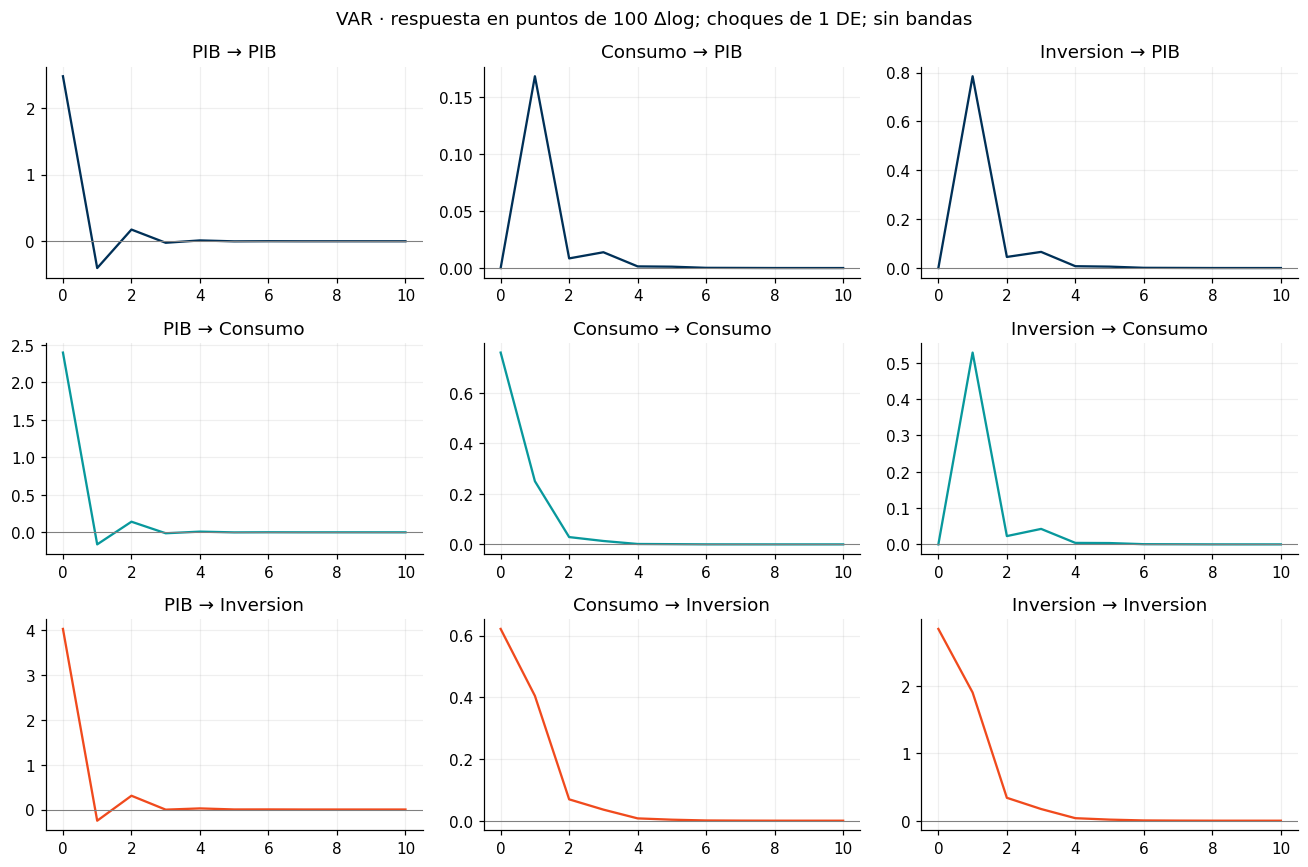

Cholesky impone orden [PIB, Consumo, Inversion]; no se identifica un choque de política por su nombre.


In [15]:
# Funciones de impulso-respuesta 

Psi_VAR = Modelo_VAR.ma_rep(maxn=H) if p_VAR else np.concatenate([np.eye(3)[None],np.zeros((H,3,3))])
P_VAR = np.linalg.cholesky(Modelo_VAR.sigma_u)
IRF_ort_VAR = Psi_VAR@P_VAR
IRF_gen_VAR = (Psi_VAR@np.asarray(Modelo_VAR.sigma_u))/np.sqrt(np.diag(Modelo_VAR.sigma_u))[None,None,:]
IRF_VAR = pd.DataFrame([[h,Nombres[i],Nombres[j],IRF_ort_VAR[h,i,j],IRF_gen_VAR[h,i,j]] for h in range(H+1) for i in range(3) for j in range(3)],columns=['h','Respuesta','Choque','Ortogonal','Generalizada'])
display(IRF_VAR.query('h<=1'))
IRF_VAR.to_csv(SALIDA/'08_VAR_IRF.csv',index=False,encoding='utf-8-sig')
Fig_IRF,Ejes=plt.subplots(3,3,figsize=(12,8))
for i in range(3):
    for j in range(3):
        Ejes[i,j].plot(range(H+1),IRF_ort_VAR[:,i,j],color=Colores[i]);Ejes[i,j].axhline(0,color='gray',lw=.7);Ejes[i,j].set_title(Nombres[j]+' → '+Nombres[i])
Fig_IRF.suptitle('VAR · respuesta en puntos de 100 Δlog; choques de 1 DE; sin bandas')
Fig_IRF.tight_layout()
for Ext in ['png','svg']:
    Fig_IRF.savefig(SALIDA/f'08_VAR_IRF.{Ext}',bbox_inches='tight')
plt.show()
print('Cholesky impone orden [PIB, Consumo, Inversion]; no se identifica un choque de política por su nombre.')
